# 01 — `return-risk` model: training results on AWS

Re-reads MLflow run `mysterious-flea-253` (Kubeflow pipeline `return_risk_training` on EKS) from the committed evidence file
[`mlflow-model-lineage.json`](../docs/evidence/aws/mlflow-model-lineage.json), then answers two questions:
by how much does the model beat the baseline, and which data produced this model.

The notebook only reads files in the repo; no AWS connection is needed. Run: `uv run --with jupyter --with matplotlib --with pandas jupyter nbconvert --execute --inplace notebooks/01_model_training_evidence.ipynb`.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
EVIDENCE = ROOT / "docs" / "evidence"
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
lineage = json.loads((EVIDENCE / "aws" / "mlflow-model-lineage.json").read_text())
m, params, tags = lineage["metrics"], lineage["params"], lineage["tags"]
print("model :", lineage["model"]["name"], "v" + lineage["model"]["version"])
print("run   :", lineage["run_name"], lineage["run_id"])
print("algorithm:", params["algo"], "| seed:", params["seed"])
print("features :", *params["features"].split(","), sep="\n  - ")

model : return-risk v1
run   : mysterious-flea-253 adba2b9f197e4e60a141acaf19682a61
algorithm: lightgbm | seed: 7
features :
  - channel
  - country
  - ordered_basis_qty
  - ordered_product_net_minor
  - unit_price_minor
  - labeled_count_90d
  - return_or_refund_rate_90d
  - approved_returns_24h


## Model vs. baseline

The baseline is the SKU's 90-day Return-or-Refund rate (nothing is learned). The metric is PR-AUC (average precision) on the **same** test set, because the label is imbalanced
(about 11% are Return/Refund), so the "random guess" reference is the positive rate `prevalence`.

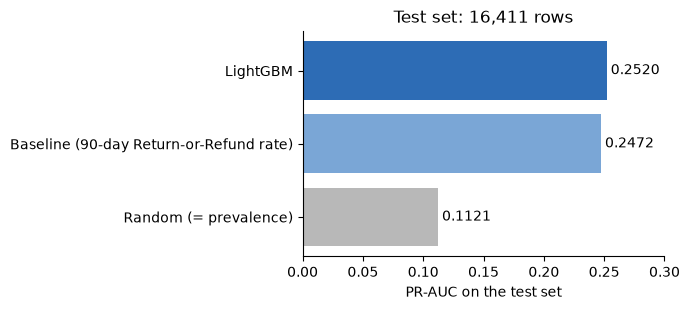

In [3]:
rows = {
    "Random (= prevalence)": m["prevalence"],
    "Baseline (90-day Return-or-Refund rate)": m["pr_auc_baseline"],
    "LightGBM": m["pr_auc_model"],
}
fig, ax = plt.subplots(figsize=(7, 3.2))
bars = ax.barh(list(rows), list(rows.values()), color=["#b8b8b8", "#7aa6d6", "#2d6cb5"])
ax.bar_label(bars, fmt="%.4f", padding=3)
ax.set_xlim(0, 0.3)
ax.set_xlabel("PR-AUC on the test set")
ax.set_title(f"Test set: {int(m['test_rows']):,} rows")
plt.tight_layout()
plt.show()

In [4]:
gap = m["pr_auc_model"] - m["pr_auc_baseline"]
print(
    f"lift over random   : {m['pr_auc_model'] / m['prevalence']:.2f}x (MLflow logged {m['lift_model']:.2f}x)"
)
print(f"gain over baseline : {gap:+.4f} PR-AUC = {gap / m['pr_auc_baseline']:+.1%} relative")
assert abs(m["pr_auc_model"] / m["prevalence"] - m["lift_model"]) < 1e-9, (
    "lift in MLflow differs from the recomputed value"
)
assert m["beats_baseline"] == 1.0

lift over random   : 2.25x (MLflow logged 2.25x)
gain over baseline : +0.0048 PR-AUC = +1.9% relative


**Reading the results.** The model is more than twice as good as random (lift 2.25), but beats the baseline by only about 0.005 PR-AUC (~2% relative).
This is **one run, one seed, no confidence interval**, so it is enough for the pipeline to set `production` under the "beats baseline" rule but not enough to claim
the model is meaningfully better than the simple rule in a statistical sense. A firm conclusion needs multiple seeds or a bootstrap over the test set.

## The data that produced this model

The `data.*` tags are written to the run by the `register` step: source path, data generation run and SHA-256 of train/test. The script
[`mlflow_run_data_proof.py`](../scripts/evidence/mlflow_run_data_proof.py) has checked the SHA-256 of the `data/train` and `data/test` artifacts against these tags (they match).

In [5]:
pd.Series(tags, name="value").to_frame()

,value
data.dataset_version,order_snapshots
data.entity_path,s3://platform-665116832975-lakehouse/feature-s...
data.generation_id,manual__2026-10-28T16:18:15.667507+00:00
data.test_sha256,963a7b8bfd52fa50ac15aa1b95b772a06cfb2204a419fa...
data.train_sha256,eb155450ca577fca53e9a6a86c21e284763f4dbc9c68b4...
